 ## Part B — NRT against MY on the same days



 The MY chlorophyll dataset is extended with interim data (MYINT) about 10 days behind real time, so MY and

 the NRT archive now overlap. On the overlapping days we compare:



 1. **Coverage**: which pixels each product observes.

 2. **Values**: how far NRT is from MY where both observe.

 3. **The decisive test**: the model and the blend rule with chlorophyll **inputs** from NRT or MY, scored

    against **targets** from NRT or MY, on the same pixel-days. Temperature is NRT in all four cases.

In [1]:
import json
from datetime import datetime, timezone

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from chlforecast import archive, config, forecast, scoring
from chlforecast import features as F

bundle = joblib.load(config.MODEL_PATH)
mask = bundle["model_mask"].values == 1
latitude = bundle["model_mask"].latitude.values
longitude = bundle["model_mask"].longitude.values
horizons = [int(h) for h in bundle["forecast_horizons_days"]]
min_chl = bundle["preprocessing"]["min_plausible_chl_mg_m3"]
METHODS = ["Forecast model", "Blend rule", "No change"]

# Live data: the NRT archive, on one daily calendar, exactly as in step 07.
chl_dates, chl_values, _ = archive.load("chl", latitude, longitude)
sst_dates, sst_values, _ = archive.load("sst", latitude, longitude)
chl_values = F.quality_control(chl_values, minimum=min_chl)
live_dates = pd.date_range(chl_dates[0], max(chl_dates[-1] + pd.Timedelta(days=config.CHL_LAG_DAYS), sst_dates[-1]))


def on_calendar(source_dates, values):
    out = np.full((len(live_dates),) + values.shape[1:], np.nan, dtype="float32")
    keep = source_dates.isin(live_dates)
    out[live_dates.get_indexer(source_dates[keep])] = values[keep]
    return out


live = {"chl": on_calendar(chl_dates, chl_values), "sst": on_calendar(sst_dates, sst_values), "dates": live_dates}
# From the first issue day with a complete history to the last archived chlorophyll day.
first_issue = chl_dates[0] + pd.Timedelta(days=config.CHL_HISTORY_DAYS + config.CHL_LAG_DAYS - 1)
last_target = chl_dates[-1]


def build_inputs(block, hide_sst=False):
    """The model's inputs, built by the shared recipe (step 04)."""
    sst = np.full_like(block["sst"], np.nan) if hide_sst else block["sst"]
    inputs = F.model_inputs(block["chl"], sst, block["dates"], mask, bundle["monthly_log_climatology"].values,
                            bundle["monthly_sst_climatology"].values, bundle["coast_distance_km"].values,
                            latitude, longitude)
    return {name: np.broadcast_to(values, block["chl"].shape) for name, values in inputs.items()}


def summarise(parts, label):
    """Scores and gain over the blend, pooling forecasts from one or more periods."""
    rows = []
    for h in horizons:
        pooled = {key: np.concatenate([p[h][key] for p in parts]) for key in ["observed", "day"] + METHODS}
        n_days = np.unique(pooled["day"]).size
        gain, low, high = (scoring.log_rmse_gain_interval(
            pooled["observed"], pooled["Forecast model"], pooled["Blend rule"], pooled["day"])
            if n_days >= 10 else (np.nan, np.nan, np.nan))
        row = {"Data": label, "Horizon": f"+{h}d", "Issue days": n_days,
               "Pixel-days per issue day": pooled["observed"].size / n_days}
        for method in METHODS:
            row[f"RMSE log10: {method}"] = scoring.chl_scores(pooled["observed"], pooled[method])["RMSE (log10)"]
        row.update({"Gain over blend (%)": gain, "95% low": low, "95% high": high})
        rows.append(row)
    return rows


TABLE_FORMAT = {"Issue days": "{:,.0f}", "Pixel-days per issue day": "{:,.0f}",
                **{f"RMSE log10: {m}": "{:.4f}" for m in METHODS},
                "Gain over blend (%)": "{:+.1f}", "95% low": "{:+.1f}", "95% high": "{:+.1f}"}

# The live forecasts, scored with the rules of step 07 (used in section 5).
live_inputs = build_inputs(live)
live_forecasts = {}
for h in horizons:
    issue_index = np.flatnonzero((live_dates >= first_issue) & (live_dates + pd.Timedelta(days=h) <= last_target))
    model = forecast.model_forecast(bundle, live_inputs, live_dates, h)[issue_index]
    blend = forecast.blend_forecast(bundle, live_inputs, live_dates, h)[issue_index]
    persistence = live_inputs["chl_latest"][issue_index]
    target = live["chl"][issue_index + h]
    scored = (np.isfinite(target) & (target > 0) & mask[None]
              & np.isfinite(persistence) & np.isfinite(model))
    live_forecasts[h] = {
        "observed": target[scored],
        "day": np.broadcast_to(live_dates[issue_index].values[:, None, None], scored.shape)[scored],
        "Forecast model": model[scored], "Blend rule": blend[scored], "No change": persistence[scored]}

# Where this run's results are saved.
run = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
out_dir = config.PROCESSED / "my_vs_nrt" / f"{run}_part_b"
out_dir.mkdir(parents=True, exist_ok=True)
(out_dir / "provenance.json").write_text(json.dumps({
    "saved_utc": datetime.now(timezone.utc).isoformat(),
    "model_file": config.MODEL_PATH.name,
    "model_training_issue_dates": bundle["training_issue_date_range"],
    "live_chl_archive_days": [f"{chl_dates[0]:%Y-%m-%d}", f"{chl_dates[-1]:%Y-%m-%d}"],
    "first_complete_issue_day": f"{first_issue:%Y-%m-%d}",
}, indent=2), encoding="utf-8")
print(f"Model: {config.MODEL_PATH.name}; live issue days from {first_issue:%Y-%m-%d}, "
      f"targets up to {last_target:%Y-%m-%d}; results to {out_dir.relative_to(config.BASE)}")


Model: chl_forecast_step09.joblib; live issue days from 2026-10-26, targets up to 2026-11-26; results to data/processed/my_vs_nrt/20261127T134238Z_part_b


In [2]:
import copernicusmarine

MY_DATASET_ID = "cmems_obs-oc_med_bgc-plankton_my_l3-multi-1km_P1D"
# MY days with fewer valid pixels than this share of the NRT pixels on the same day are
# treated as not yet complete, and the overlap ends before the first of them.
MY_COMPLETE_SHARE = 0.5

retrieved_utc = datetime.now(timezone.utc)
remote = copernicusmarine.open_dataset(
    dataset_id=MY_DATASET_ID, variables=["CHL"],
    start_datetime=f"{chl_dates[0] - pd.Timedelta(days=25):%Y-%m-%d}", end_datetime=f"{chl_dates[-1]:%Y-%m-%d}",
    **config.REGION)
my_recent = remote["CHL"].sortby("latitude").sortby("longitude").load()
for coord, target in [("latitude", latitude), ("longitude", longitude)]:
    if my_recent.sizes[coord] != target.size or not np.allclose(my_recent[coord].values, target, atol=1e-5, rtol=0):
        raise ValueError(f"MY {coord} does not match the model grid")

# Keep the copy used, so this comparison can be repeated exactly.
my_copy = config.DATA / "raw" / "my_recent" / f"chl_my_{retrieved_utc:%Y%m%dT%H%M%SZ}.nc"
my_copy.parent.mkdir(parents=True, exist_ok=True)
my_recent.to_dataset(name="CHL").assign_attrs(
    source_dataset_id=MY_DATASET_ID, retrieved_utc=retrieved_utc.isoformat()).to_netcdf(my_copy)

my_dates = pd.DatetimeIndex(my_recent.time.values)
my_values = F.quality_control(my_recent.values, minimum=min_chl)
my_chl = on_calendar(my_dates, my_values)  # on the live calendar: same history length as NRT

# Coverage per day, over the modelled pixels.
nrt_valid = np.isfinite(live["chl"]) & mask[None]
my_valid = np.isfinite(my_chl) & mask[None]
coverage = pd.DataFrame({
    "NRT pixels": nrt_valid.sum((1, 2)),
    "MY pixels": my_valid.sum((1, 2)),
    "Both": (nrt_valid & my_valid).sum((1, 2)),
    "NRT only": (nrt_valid & ~my_valid).sum((1, 2)),
    "MY only": (~nrt_valid & my_valid).sum((1, 2)),
}, index=live_dates.rename("Date"))
coverage = coverage.loc[chl_dates[0]:chl_dates[-1]]
incomplete = coverage.index[(coverage["MY pixels"] < MY_COMPLETE_SHARE * coverage["NRT pixels"])
                            & (coverage.index > my_dates[-1] - pd.Timedelta(days=7))]
my_last = min((incomplete[0] - pd.Timedelta(days=1)) if len(incomplete) else my_dates[-1], my_dates[-1])
overlap = coverage.loc[:my_last]
print(f"MY retrieved {retrieved_utc:%Y-%m-%d %H:%M} UTC, saved to {my_copy.relative_to(config.BASE)}")
print(f"MY offers {my_dates[0]:%Y-%m-%d} to {my_dates[-1]:%Y-%m-%d}; complete to {my_last:%Y-%m-%d}; "
      f"overlap with NRT {len(overlap)} days")


INFO - 2026-11-27T13:42:40Z - Selected dataset version: "202611"
INFO - 2026-11-27T13:42:40Z - Selected dataset part: "default"
WARNING - 2026-11-27T13:42:40Z - Some of your subset selection [2026-09-24 00:00:00+00:00, 2026-11-26 00:00:00+00:00] for the time dimension exceed the dataset coordinates [1997-09-16 00:00:00+00:00, 2026-11-19 00:00:00+00:00]


MY retrieved 2026-11-27 13:42 UTC, saved to data/raw/my_recent/chl_my_20261127T134238Z.nc
MY offers 2026-09-24 to 2026-11-19; complete to 2026-11-19; overlap with NRT 32 days


 ### 1. Coverage



 Share of the pixels observed by either product, on the overlapping days.

,Value
Days,32
NRT pixel-days,"168,110"
MY pixel-days,"198,091"
NRT as share of MY (%),84.9
Observed by both (% of either),74.5
MY only (% of either),19.9
NRT only (% of either),5.6


,NRT pixels,MY pixels,Both,NRT only,MY only
Date,,,,,
2026-10-19,6,6,6,0,0
2026-10-20,1094,3267,884,210,2383
2026-10-21,962,716,716,246,0
2026-10-22,12152,12062,12062,90,0
2026-10-23,11955,11785,11749,206,36
2026-10-24,0,0,0,0,0
2026-10-25,39,168,38,1,130
2026-10-26,2773,2329,1976,797,353
2026-10-27,1904,11532,1904,0,9628


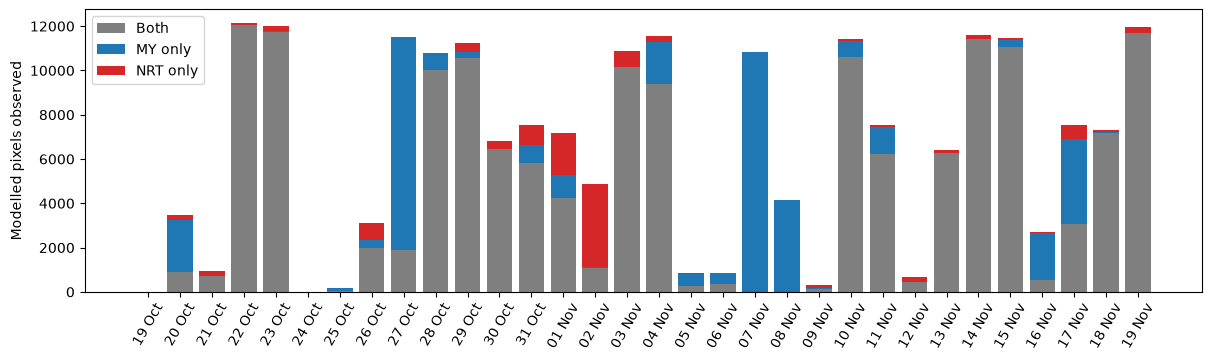

In [3]:
either = overlap["Both"] + overlap["NRT only"] + overlap["MY only"]
totals = overlap.sum()
display(pd.Series({
    "Days": len(overlap),
    "NRT pixel-days": f"{totals['NRT pixels']:,}",
    "MY pixel-days": f"{totals['MY pixels']:,}",
    "NRT as share of MY (%)": f"{100 * totals['NRT pixels'] / totals['MY pixels']:.1f}",
    "Observed by both (% of either)": f"{100 * totals['Both'] / either.sum():.1f}",
    "MY only (% of either)": f"{100 * totals['MY only'] / either.sum():.1f}",
    "NRT only (% of either)": f"{100 * totals['NRT only'] / either.sum():.1f}",
}).to_frame("Value"))
display(overlap)

fig_cov, ax = plt.subplots(figsize=(12, 3.5), constrained_layout=True)
x = np.arange(len(overlap))
ax.bar(x, overlap["Both"], label="Both", color="tab:grey")
ax.bar(x, overlap["MY only"], bottom=overlap["Both"], label="MY only", color="tab:blue")
ax.bar(x, overlap["NRT only"], bottom=overlap["Both"] + overlap["MY only"], label="NRT only", color="tab:red")
ax.set_xticks(x, [f"{d:%d %b}" for d in overlap.index], rotation=60)
ax.set_ylabel("Modelled pixels observed")
ax.legend()
plt.show()


 ### 2. Values where both observe



 Differences in log10 (NRT minus MY). For scale: the published accuracy of MY itself is an RMSD of 0.25 in

 log10, and the blend rule's live +1d error is about 0.13.

,Pixel-days,Bias (log10),S.d. (log10),RMSD (log10),Correlation,NRT/MY median ratio,Share within ±0.05 log10 (%)
Days,,,,,,,
All overlap,"156,314",-0.1029,0.0500,0.1144,0.960,0.801,6.6
2026-10-20,884,-0.0823,0.0178,0.0842,0.930,0.832,2.7
2026-10-21,716,-0.0869,0.0090,0.0873,0.987,0.813,0.7
2026-10-22,"12,062",-0.0784,0.0290,0.0835,0.974,0.839,5.1
2026-10-23,"11,749",-0.1004,0.0353,0.1064,0.954,0.778,10.3
2026-10-26,"1,976",-0.0884,0.0333,0.0945,0.974,0.814,1.5
2026-10-27,"1,904",-0.0856,0.0894,0.1238,0.899,0.850,26.7
2026-10-28,"10,021",-0.0809,0.0601,0.1008,0.866,0.849,23.8
2026-10-29,"10,544",-0.1174,0.0271,0.1205,0.953,0.766,1.0


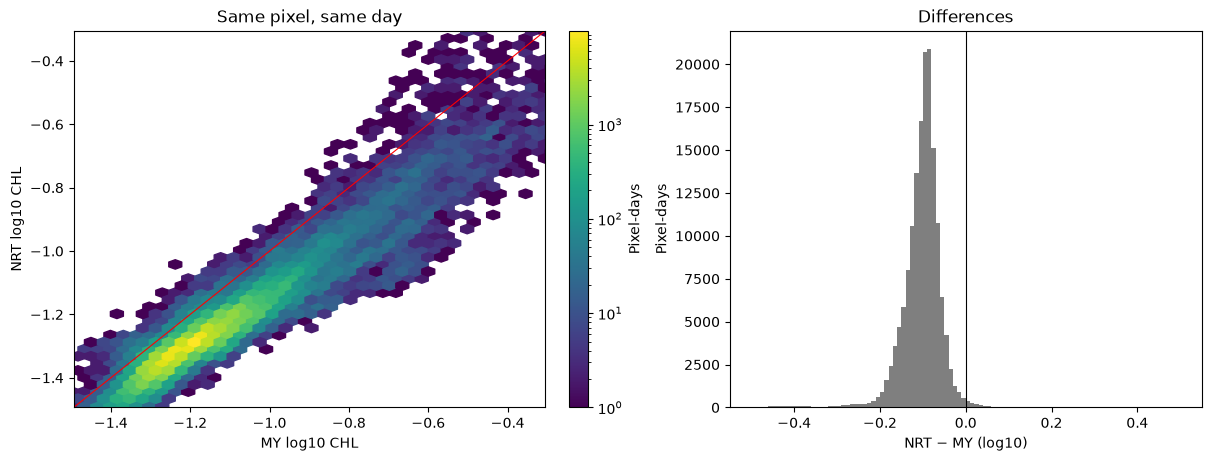

In [4]:
both = nrt_valid & my_valid & (np.arange(len(live_dates)) <= live_dates.get_loc(my_last))[:, None, None]
log_nrt, log_my = np.log10(live["chl"][both]), np.log10(my_chl[both])
difference = log_nrt - log_my
day_of = np.broadcast_to(np.arange(len(live_dates))[:, None, None], both.shape)[both]


def difference_scores(d, a, b):
    return {"Pixel-days": d.size, "Bias (log10)": d.mean(), "S.d. (log10)": d.std(),
            "RMSD (log10)": np.sqrt(np.mean(d ** 2)), "Correlation": np.corrcoef(a, b)[0, 1],
            "NRT/MY median ratio": 10 ** np.median(d),
            "Share within ±0.05 log10 (%)": 100 * np.mean(np.abs(d) <= 0.05)}


values_overall = pd.DataFrame([{"Days": "All overlap", **difference_scores(difference, log_nrt, log_my)}]
                              + [{"Days": f"{live_dates[k]:%Y-%m-%d}", **difference_scores(difference[day_of == k], log_nrt[day_of == k], log_my[day_of == k])}
                                 for k in np.unique(day_of) if (day_of == k).sum() >= 100]).set_index("Days")
display(values_overall.style.format({"Pixel-days": "{:,.0f}", "Bias (log10)": "{:+.4f}", "S.d. (log10)": "{:.4f}",
                                     "RMSD (log10)": "{:.4f}", "Correlation": "{:.3f}", "NRT/MY median ratio": "{:.3f}",
                                     "Share within ±0.05 log10 (%)": "{:.1f}"}))

fig_val, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
hb = axes[0].hexbin(log_my, log_nrt, gridsize=80, bins="log", mincnt=1, cmap="viridis")
lims = np.nanpercentile(np.concatenate([log_my, log_nrt]), [0.5, 99.5])
axes[0].plot(lims, lims, color="red", lw=0.8)
axes[0].set(xlim=lims, ylim=lims, xlabel="MY log10 CHL", ylabel="NRT log10 CHL", title="Same pixel, same day")
fig_val.colorbar(hb, ax=axes[0], label="Pixel-days")
axes[1].hist(difference, bins=np.linspace(-0.5, 0.5, 101), color="tab:grey")
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set(xlabel="NRT − MY (log10)", ylabel="Pixel-days", title="Differences")
plt.show()


 ### 3. The decisive test



 Four combinations of where the chlorophyll inputs and the targets come from, scored on **the same

 pixel-days** (both targets observed, both latest observations usable). Reading it:



 * **MY inputs, MY targets** should resemble Part A's MY result (model ahead of the blend). If it does not,

   the live pipeline itself differs from training.

 * **NRT inputs, MY targets**: if the model falls behind here, NRT **inputs** mislead it.

 * **MY inputs, NRT targets**: if the model falls behind here, NRT **targets** penalise it (the blend's

   smoother forecasts suffer less from noisy truth).

In [5]:
my_live = {"chl": my_chl, "sst": live["sst"], "dates": live_dates}
sources = {"NRT": live, "MY": my_live}
source_inputs = {name: build_inputs(block) for name, block in sources.items()}

rows = []
for h in horizons:
    issue_index = np.flatnonzero((live_dates >= first_issue) & (live_dates + pd.Timedelta(days=h) <= my_last))
    if issue_index.size == 0:
        continue
    issue_dates = live_dates[issue_index]
    predicted = {}
    for name in sources:
        inputs = source_inputs[name]
        predicted[name] = {
            "Forecast model": forecast.model_forecast(bundle, inputs, live_dates, h)[issue_index],
            "Blend rule": forecast.blend_forecast(bundle, inputs, live_dates, h)[issue_index],
            "No change": inputs["chl_latest"][issue_index]}
    targets = {name: block["chl"][issue_index + h] for name, block in sources.items()}
    common = np.broadcast_to(mask, targets["NRT"].shape).copy()
    for name in sources:
        common &= np.isfinite(targets[name]) & (targets[name] > 0)
        common &= np.isfinite(predicted[name]["No change"]) & np.isfinite(predicted[name]["Forecast model"])
    day = np.broadcast_to(issue_index[:, None, None], common.shape)[common]
    n_days = np.unique(day).size
    for input_name in sources:
        for target_name in sources:
            observed = targets[target_name][common]
            p = {m: predicted[input_name][m][common] for m in METHODS}
            gain, low, high = (scoring.log_rmse_gain_interval(observed, p["Forecast model"], p["Blend rule"], day)
                               if n_days >= 10 else
                               (100 * (1 - scoring.chl_scores(observed, p["Forecast model"])["RMSE (log10)"]
                                       / scoring.chl_scores(observed, p["Blend rule"])["RMSE (log10)"]), np.nan, np.nan))
            rows.append({"Horizon": f"+{h}d", "Inputs": input_name, "Targets": target_name,
                         "Issue days": n_days, "Pixel-days": int(common.sum()),
                         **{f"RMSE log10: {m}": scoring.chl_scores(observed, p[m])["RMSE (log10)"] for m in METHODS},
                         "Gain over blend (%)": gain, "95% low": low, "95% high": high})

decisive = pd.DataFrame(rows).set_index(["Horizon", "Inputs", "Targets"])
display(decisive.style.format({**TABLE_FORMAT, "Pixel-days": "{:,.0f}"}, na_rep="needs 10+ days"))


 ### 4. Pipeline check: MY with a long history



 The live calendar starts on the first archived NRT day, so early issue days have a shorter look-back than in

 training. Here MY is scored with 25 extra days of history, as in Part A. If the result matches the MY/MY row

 above, the short calendar is not the cause.

In [6]:
long_dates = my_dates
long_sst = np.full_like(my_values, np.nan)
keep = sst_dates.isin(long_dates)
long_sst[long_dates.get_indexer(sst_dates[keep])] = sst_values[keep]
long_block = {"chl": my_values, "sst": long_sst, "dates": long_dates}
long_inputs = build_inputs(long_block)
long_parts = {}
for h in horizons:
    issue_index = np.flatnonzero((long_dates >= first_issue) & (long_dates + pd.Timedelta(days=h) <= my_last))
    if issue_index.size == 0:
        continue
    target = my_values[issue_index + h]
    p = {"Forecast model": forecast.model_forecast(bundle, long_inputs, long_dates, h)[issue_index],
         "Blend rule": forecast.blend_forecast(bundle, long_inputs, long_dates, h)[issue_index],
         "No change": long_inputs["chl_latest"][issue_index]}
    scored = (np.isfinite(target) & (target > 0) & mask[None]
              & np.isfinite(p["No change"]) & np.isfinite(p["Forecast model"]))
    long_parts[h] = {"observed": target[scored],
                     "day": np.broadcast_to(long_dates[issue_index].values[:, None, None], scored.shape)[scored],
                     **{m: v[scored] for m, v in p.items()}}
pipeline_check = pd.DataFrame([r for r in summarise([long_parts], f"MY {last_target.year}, long history")
                               if int(r["Horizon"][1:-1]) in long_parts]).set_index(["Horizon", "Data"])
display(pipeline_check.style.format(TABLE_FORMAT, na_rep="needs 10+ days"))


,,Issue days,Pixel-days per issue day,RMSE log10: Forecast model,RMSE log10: Blend rule,RMSE log10: No change,Gain over blend (%),95% low,95% high
Horizon,Data,,,,,,,,
+1d,"MY 2026, long history",24,"6,990",0.1441,0.1524,0.1778,+5.5,+0.7,+13.1
+4d,"MY 2026, long history",21,"6,408",0.1700,0.1664,0.2181,-2.1,-6.1,+11.0
+7d,"MY 2026, long history",18,"6,456",0.1711,0.1632,0.2124,-4.9,-9.5,+8.0


 ### 5. Day by day



 The live result (NRT inputs and targets, all archived days) per issue day. A few days of sharp change can

 outweigh many ordinary days, because errors are squared. "Observed change" is the target minus the latest

 observation, in log10: positive means chlorophyll rose.

In [7]:
DAY_HORIZON = 1

part = live_forecasts[DAY_HORIZON]
log_observed = np.log10(part["observed"])
per_day = []
for day in np.unique(part["day"]):
    on = part["day"] == day
    errors = {m: np.log10(part[m][on]) - log_observed[on] for m in ["Forecast model", "Blend rule"]}
    rmse = {m: np.sqrt(np.mean(e ** 2)) for m, e in errors.items()}
    per_day.append({
        "Issue day": f"{pd.Timestamp(day):%Y-%m-%d}",
        "Pixel-days": int(on.sum()),
        "Observed change (log10)": float(np.mean(log_observed[on] - np.log10(part["No change"][on]))),
        "RMSE: model": rmse["Forecast model"], "RMSE: blend": rmse["Blend rule"],
        "Bias: model": float(errors["Forecast model"].mean()), "Bias: blend": float(errors["Blend rule"].mean()),
        "Better": "Model" if rmse["Forecast model"] < rmse["Blend rule"] else "Blend",
        # Share of the whole period's excess squared error (model minus blend) from this day.
        "Excess error share (%)": float(np.sum(errors["Forecast model"] ** 2 - errors["Blend rule"] ** 2)),
    })
per_day = pd.DataFrame(per_day).set_index("Issue day")
per_day["Excess error share (%)"] *= 100 / per_day["Excess error share (%)"].sum()
print(f"+{DAY_HORIZON}d: model better on {(per_day['Better'] == 'Model').sum()} of {len(per_day)} issue days")
display(per_day.style.format({"Pixel-days": "{:,.0f}", "Observed change (log10)": "{:+.3f}",
                              "RMSE: model": "{:.4f}", "RMSE: blend": "{:.4f}", "Bias: model": "{:+.4f}",
                              "Bias: blend": "{:+.4f}", "Excess error share (%)": "{:+.0f}"}))


+1d: model better on 21 of 29 issue days


,Pixel-days,Observed change (log10),RMSE: model,RMSE: blend,Bias: model,Bias: blend,Better,Excess error share (%)
Issue day,,,,,,,,
2026-10-26,"1,904",+0.037,0.0371,0.0547,-0.0057,-0.0348,Model,+4
2026-10-27,"10,017",+0.006,0.0586,0.0492,+0.0260,-0.0140,Blend,-12
2026-10-28,"10,901",-0.079,0.1495,0.1193,+0.1052,+0.0669,Blend,-106
2026-10-29,"6,795",-0.019,0.0649,0.0537,+0.0318,+0.0048,Blend,-11
2026-10-30,"6,703",+0.047,0.1012,0.1080,+0.0008,-0.0257,Model,+11
2026-10-31,"6,146",+0.073,0.0624,0.0680,-0.0402,+0.0017,Model,+5
2026-11-01,"4,862",+0.157,0.1479,0.1346,-0.1074,-0.0927,Blend,-22
2026-11-02,"10,849",+0.148,0.2493,0.2342,-0.1121,-0.0923,Blend,-95
2026-11-03,"9,617",+0.109,0.1338,0.1422,-0.0754,-0.0796,Model,+27


In [8]:
for name, table in [("overlap_coverage", overlap), ("overlap_values", values_overall),
                    ("inputs_targets_test", decisive), ("pipeline_check", pipeline_check),
                    (f"live_by_issue_day_{DAY_HORIZON}d", per_day)]:
    table.reset_index().to_json(out_dir / f"{name}.json", orient="records", indent=2, double_precision=10,
                                date_format="iso")
fig_cov.savefig(out_dir / "overlap_coverage.png", dpi=150)
fig_val.savefig(out_dir / "overlap_values.png", dpi=150)
provenance = json.loads((out_dir / "provenance.json").read_text())
provenance.update({
    "my_dataset_id": MY_DATASET_ID,
    "my_copy": str(my_copy.relative_to(config.BASE)),
    "my_retrieved_utc": retrieved_utc.isoformat(),
    "my_complete_to": f"{my_last:%Y-%m-%d}",
    "overlap_days": [f"{overlap.index[0]:%Y-%m-%d}", f"{overlap.index[-1]:%Y-%m-%d}"],
    "decisive_test_temperature": "NRT in all four combinations",
})
(out_dir / "provenance.json").write_text(json.dumps(provenance, indent=2), encoding="utf-8")
print(f"Saved Part B to {out_dir}")


Saved Part B to /Users/alangatt/git/mcast/research/mcast.pages.chl_prediction/experiment_v2/data/processed/my_vs_nrt/20261127T134238Z_part_b
